In [2]:
import tensorflow as tf 
from sklearn.preprocessing import LabelEncoder,StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,f1_score

In [3]:
data=pd.read_csv("fashion-mnist_train.csv")
data.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
data.shape

(60000, 785)

In [5]:
X=data.drop('label',axis=1)
y=data.label

In [6]:
sc=StandardScaler()
X=sc.fit_transform(X)

In [7]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y)


# parameters

In [8]:
optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
initialization=tf.keras.initializers.GlorotUniform(seed=42)
regularization=tf.keras.regularizers.L2(l2=.02)


In [9]:
model=tf.keras.Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),

        tf.keras.layers.Dense(
            800,
            kernel_initializer= initialization                   
        ),
        
        tf.keras.layers.Activation(activation='relu'),
        tf.keras.layers.Dropout(rate=.4, seed=42),
        

        tf.keras.layers.Dense(
            400,
            kernel_initializer=initialization
            
        ),
         
        tf.keras.layers.Activation(activation='relu'),
        tf.keras.layers.Dropout(rate=.3,seed=42),


           tf.keras.layers.Dense(
            200,
            kernel_initializer=initialization
             
        ),
         
        tf.keras.layers.Activation(activation='relu'),
        tf.keras.layers.Dropout(rate=.2,seed=42),

           tf.keras.layers.Dense(
            100,
            kernel_initializer=initialization
             
        ),
         
        tf.keras.layers.Activation(activation='relu'),
        tf.keras.layers.Dropout(rate=.1,seed=42),

        tf.keras.layers.Dense(
            10,
            kernel_initializer=initialization
        )        
    ]
        
    )


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 800)                 │         628,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 400)                 │         320,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 400)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 400)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 200)                 │          80,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 100)                 │          20,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,049,710 (4.00 MB)

 Trainable params: 1,049,710 (4.00 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

In [12]:
history=model.fit(X_train,y_train,
                validation_data=[X_test,y_test],
                # batch_size=32,
                epochs=20 )

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.7794 - loss: 0.6214 - val_accuracy: 0.8397 - val_loss: 0.4408
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8315 - loss: 0.4840 - val_accuracy: 0.8528 - val_loss: 0.3956
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8433 - loss: 0.4462 - val_accuracy: 0.8568 - val_loss: 0.3918
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8542 - loss: 0.4232 - val_accuracy: 0.8677 - val_loss: 0.3845
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8591 - loss: 0.4089 - val_accuracy: 0.8745 - val_loss: 0.3511
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8633 - loss: 0.3924 - val_accuracy: 0.8735 - val_loss: 0.3572
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8665 - loss: 0.3828 - val_accuracy: 0.8775 - val_loss: 0.3407
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8671 - loss: 0

In [13]:
loss_df=pd.DataFrame(history.history)
loss_df

,accuracy,loss,val_accuracy,val_loss
0,0.779396,0.621370,0.839750,0.440757
1,0.831542,0.483970,0.852750,0.395640
2,0.843313,0.446172,0.856833,0.391753
3,0.854208,0.423231,0.867667,0.384536
4,0.859083,0.408913,0.874500,0.351080
5,0.863333,0.392384,0.873500,0.357190
6,0.866500,0.382785,0.877500,0.340677
7,0.867083,0.381624,0.875750,0.349841
8,0.873958,0.365222,0.883333,0.334149
9,0.876500,0.352715,0.889750,0.326313


In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap

def fn_plot_tf_hist(hist_df):
    """
    Plots training history with side-by-side Loss and Accuracy curves.
    Automatically highlights the best epoch based on minimum validation loss.
    """
    # 1. Create the figure and axes layout
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Custom colormap: Blue for training, Red/Crimson for validation
    CMAP = ListedColormap(['#3F51B5', '#D32F2F'])
    
    # 2. Get columns by index to eliminate any column naming errors
    # Expected positions: y1=accuracy, y2=loss, y3=val_accuracy, y4=val_loss
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # 3. Find the best epoch details based on minimum validation loss
    min_loss_row = hist_df[hist_df[y4] == hist_df[y4].min()]
    best_epoch = min_loss_row.index[0]
    min_loss = min_loss_row[y4].values[0]
    best_acc = min_loss_row[y3].values[0]

    # ==========================================
    # LEFT PLOT: LOSS CURVE
    # ==========================================
    ax0 = axes[0]
    hist_df.plot(y=[y2, y4], ax=ax0, colormap=CMAP)
    
    # Layout and Labels
    ax0.set_title("Loss Curve", fontsize=12)
    ax0.set_xlabel("Epochs")
    ax0.set_ylabel("Loss")
    ax0.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax0.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch loss metrics (top left)
    txtFmt_loss = "Loss:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_loss = txtFmt_loss.format(hist_df.iloc[-1][y2], hist_df.iloc[-1][y4])
    ax0.text(0.2, 0.85, txtstr_loss, transform=ax0.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to the minimum validation loss
    ax0.annotate(f'Min: {min_loss:.4f}', 
                 xy=(best_epoch, min_loss), 
                 xytext=(-60, 45),            # Fixed pixel offset to the left and up
                 textcoords='offset points',  # Prevents squishing on different data scales
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='bottom')

    # ==========================================
    # RIGHT PLOT: ACCURACY CURVE
    # ==========================================
    ax1 = axes[1]
    hist_df.plot(y=[y1, y3], ax=ax1, colormap=CMAP)
    
    # Layout and Labels
    ax1.set_title("Accuracy Curve", fontsize=12)
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Accuracy")
    ax1.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax1.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch accuracy metrics (bottom center)
    txtFmt_acc = "Accuracy:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_acc = txtFmt_acc.format(hist_df.iloc[-1][y1], hist_df.iloc[-1][y3])
    ax1.text(0.3, 0.15, txtstr_acc, transform=ax1.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to accuracy at the best epoch
    ax1.annotate(f'Best: {best_acc:.4f}', 
                 xy=(best_epoch, best_acc), 
                 xytext=(-60, -35),           # Fixed pixel offset to the left and down
                 textcoords='offset points',  # Prevents squishing when accuracy hugs 1.0
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='top')

    # Final rendering tweaks
    plt.tight_layout()
    plt.show()


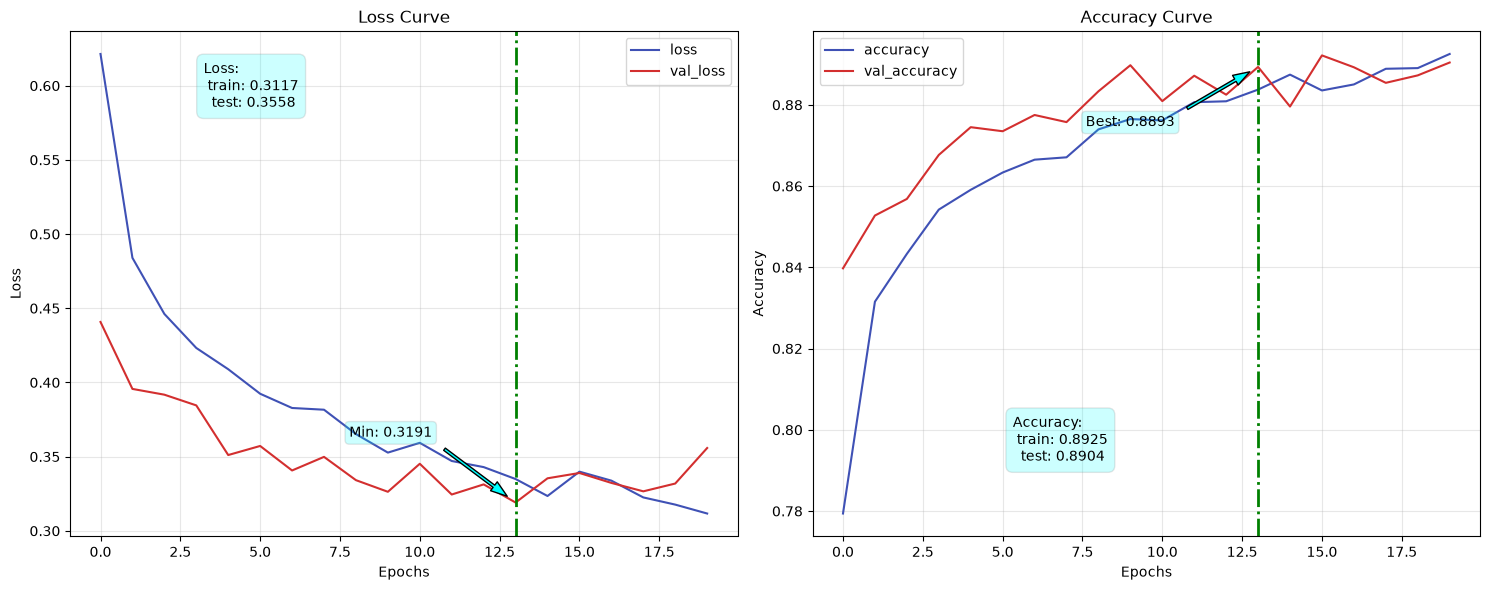

In [15]:
fn_plot_tf_hist(loss_df)